# Excess risk r(h)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

models_folder  = "*/Models"
results_folder = "*/excess_risk_analysis"
os.makedirs(results_folder, exist_ok=True)

# model name: (folder, end of the file name)
models = {
    "Chronos2":    ("Chronos2", "chronos"),
    "ChronosBOLT": ("ChronosBOLT", "chronos_bolt"),
    "Moirai":      ("Moirai", "moirai"),
    "TimesFM":     ("TimesFM", "times_fm"),
}
context_lengths = [32, 64, 128, 256, 512]
walk_column = "walk_id"      # the column that says which walk a row belongs to

# read all prediction files into one table
tables = []
for model_name, (folder, file_end) in models.items():
    for L in context_lengths:
        file_path = f"{models_folder}/{folder}/predicitons_{L}_{file_end}.csv"
        predictions = pd.read_csv(file_path)
        predictions["model"] = model_name
        predictions["L"] = L
        tables.append(predictions)

data = pd.concat(tables, ignore_index=True)
data["snr"] = data["snr"].round(6)       # remove tiny float differences

# the forecasts start at the last context point, so the naive forecast is 0
print("naive is 0 everywhere:", np.allclose(data["naive"], 0))

# the plug-in forecast is horizon * context drift, so the context drift is plugin / horizon
data["context_drift"] = data["plugin"] / data["horizon"]

cell_columns = ["model", "L", "snr", "horizon"]    # one cell = all walks with the same settings
model_names = list(models)
print(data.shape)
data.head()

naive is 0 everywhere: True
(64000000, 22)


,Unnamed: 0,walk_id,snr,seed,sigma,mu,context_len,horizon,model,checkpoint,...,naive,plugin,conditional,se_model,se_naive,se_plugin,se_conditional,L,num_samples,context_drift
0,0,snr0.01_seed0,0.01,0,1.0,0.01,32,1,Chronos2,chronos-2-amazon,...,0.0,-0.023217,0.01,0.004846,0.023383,0.031022,0.020424,32,NaN,-0.023217
1,1,snr0.01_seed0,0.01,0,1.0,0.01,32,2,Chronos2,chronos-2-amazon,...,0.0,-0.046434,0.02,0.244420,0.145195,0.111964,0.160836,32,NaN,-0.023217
2,2,snr0.01_seed0,0.01,0,1.0,0.01,32,3,Chronos2,chronos-2-amazon,...,0.0,-0.069650,0.03,0.367308,0.254516,0.189090,0.285686,32,NaN,-0.023217
3,3,snr0.01_seed0,0.01,0,1.0,0.01,32,4,Chronos2,chronos-2-amazon,...,0.0,-0.092867,0.04,0.537184,0.645413,0.803252,0.582743,32,NaN,-0.023217
4,4,snr0.01_seed0,0.01,0,1.0,0.01,32,5,Chronos2,chronos-2-amazon,...,0.0,-0.116084,0.05,0.042312,0.023853,0.001471,0.041797,32,NaN,-0.023217


In [2]:
# r(h) = (forecast - conditional mean)^2 / (h * sigma^2)
# 0 = as good as the conditional mean, 1 = own mistake is as large as the noise
noise_floor = data["horizon"] * data["sigma"] ** 2

data["r_model"]  = (data["forecast"] - data["conditional"]) ** 2 / noise_floor
data["r_plugin"] = (data["plugin"]   - data["conditional"]) ** 2 / noise_floor
data["r_naive"]  = (data["naive"]    - data["conditional"]) ** 2 / noise_floor

r_table = data.groupby(cell_columns)[["r_model", "r_plugin", "r_naive"]].agg(["mean", "median"])
r_table.columns = [f"{name}_{stat}" for name, stat in r_table.columns]    # e.g. r_model_mean
r_table = r_table.reset_index()

# ratio model / plug-in per cell: below 1 the model is better than the plug-in, above 1 worse
r_table["r_ratio_mean"]   = r_table["r_model_mean"]   / r_table["r_plugin_mean"]
r_table["r_ratio_median"] = r_table["r_model_median"] / r_table["r_plugin_median"]

r_table.to_csv(f"{results_folder}/excess_risk.csv", index=False)
r_table

,model,L,snr,horizon,r_model_mean,r_model_median,r_plugin_mean,r_plugin_median,r_naive_mean,r_naive_median,r_ratio_mean,r_ratio_median
0,Chronos2,32,0.01,1,0.102107,0.042183,0.035554,0.013107,0.0001,0.0001,2.871914,3.218311
1,Chronos2,32,0.01,2,0.106976,0.039274,0.071108,0.026214,0.0002,0.0002,1.504421,1.498179
2,Chronos2,32,0.01,3,0.123237,0.040218,0.106661,0.039321,0.0003,0.0003,1.155401,1.022807
3,Chronos2,32,0.01,4,0.152820,0.053139,0.142215,0.052428,0.0004,0.0004,1.074565,1.013552
4,Chronos2,32,0.01,5,0.186174,0.056460,0.177769,0.065536,0.0005,0.0005,1.047282,0.861510
...,...,...,...,...,...,...,...,...,...,...,...,...
639995,TimesFM,512,5.00,252,16.250130,11.268347,0.507006,0.233495,6300.0000,6300.0000,32.051159,48.259377
639996,TimesFM,512,5.00,253,16.325539,11.329258,0.509018,0.234422,6325.0000,6325.0000,32.072619,48.328461
639997,TimesFM,512,5.00,254,15.073024,10.151676,0.511030,0.235349,6350.0000,6350.0000,29.495388,43.134628
639998,TimesFM,512,5.00,255,14.904107,10.044013,0.513042,0.236275,6375.0000,6375.0000,29.050473,42.509804


In [3]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import ScalarFormatter
from matplotlib.lines import Line2D

# same order and names as the old figure
model_order = ["TimesFM", "Moirai", "Chronos2", "ChronosBOLT"]
model_labels = {"TimesFM": "TimesFM", "Moirai": "Moirai", "Chronos2": "Chronos2", "ChronosBOLT": "ChronosBolt"}
legend_fontsize = 14

# five bands of excess risk; a value exactly on an edge goes in the lower band
band_edges = [0.1, 1.0, 10.0, 100.0]
band_colors = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]
band_names = ["$r\\leq0.1$", "$(0.1, 1]$ (excess below floor)", "$(1, 10]$", "$(10, 100]$", "$r>100$"]
colormap = ListedColormap(band_colors)
color_steps = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], 5)

# the same SNR and horizon grid in every panel
snr_values = np.array(sorted(r_table["snr"].unique()))
horizon_values = np.array(sorted(r_table["horizon"].unique()))

# legend: the five bands and the two reference lines
legend_items = []
for color, name in zip(band_colors, band_names):
    legend_items.append(plt.Rectangle((0, 0), 1, 1, color=color, label=name))
legend_items.append(Line2D([], [], color=".25", linestyle="--", linewidth=0.9, label=r"SNR $=1/\sqrt{h}$"))
legend_items.append(Line2D([], [], color=".25", linestyle="-.", linewidth=0.9, label=r"$h=T$"))

# Mean plot and table

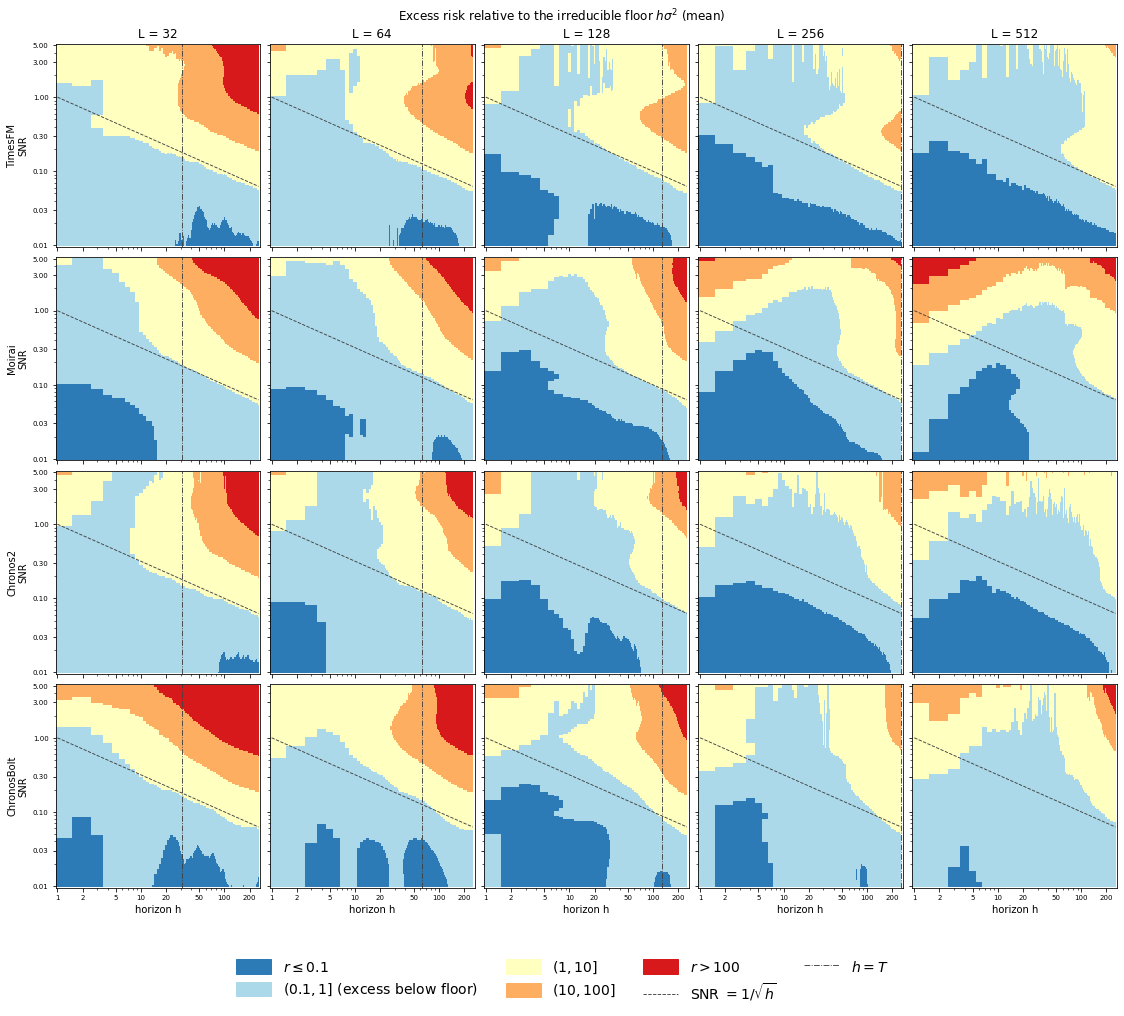

In [4]:
fig, axes = plt.subplots(len(model_order), len(context_lengths),
                         figsize=(3.1 * len(context_lengths), 3.1 * len(model_order)),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)

for row, model_name in enumerate(model_order):
    for col, L in enumerate(context_lengths):
        part = r_table[(r_table["model"] == model_name) & (r_table["L"] == L)]
        r_grid = part.pivot(index="snr", columns="horizon", values="r_model_mean")
        r_grid = r_grid.reindex(index=snr_values, columns=horizon_values).to_numpy().astype(float)

        # put every cell in one of the five bands, missing cells stay blank
        band_grid = np.digitize(r_grid, band_edges, right=True).astype(float)
        band_grid[~np.isfinite(r_grid)] = np.nan

        ax = axes[row, col]
        ax.pcolormesh(horizon_values, snr_values, np.ma.masked_invalid(band_grid),
                      cmap=colormap, norm=color_steps, shading="nearest")

        # reference lines: naive error = noise at SNR = 1/sqrt(h), plug-in error = noise at h = T
        ax.plot(horizon_values, 1 / np.sqrt(horizon_values), color=".25", linestyle="--", linewidth=0.9)
        ax.axvline(L - 1, color=".25", linestyle="-.", linewidth=0.9)

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.set_xticks([1, 2, 5, 10, 20, 50, 100, 200])
        ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1, 3, 5])
        ax.set_xlim(horizon_values.min() * 0.95, horizon_values.max() * 1.05)
        ax.set_ylim(snr_values.min() * 0.95, snr_values.max() * 1.05)
        ax.tick_params(labelsize=7)
        if row == 0:
            ax.set_title(f"L = {L}")
        if col == 0:
            ax.set_ylabel(f"{model_labels[model_name]}\nSNR")
        if row == len(model_order) - 1:
            ax.set_xlabel("horizon h")

fig.suptitle("Excess risk relative to the irreducible floor $h\\sigma^2$ (mean)", y=1.02)
fig.legend(handles=legend_items, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.11),
           fontsize=legend_fontsize, handlelength=2.5, handleheight=1.2, columnspacing=2.0)

fig.savefig(f"{results_folder}/fig2_excess_risk_mean.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
# Table 4, mean over the walks in a cell: median over all cells per L
print("=== Table 4, mean over the walks in a cell ===")

print("excess risk of the model")
model_table = r_table.pivot_table(index="model", columns="L", values="r_model_mean", aggfunc="median")
print(model_table.reindex(model_order).round(2).to_string())

# plug-in and naive are the same for every model, so take them from one model
reference = r_table[r_table["model"] == model_order[0]]
reference_table = pd.DataFrame({
    "plug-in": reference.groupby("L")["r_plugin_mean"].median(),
    "naive":   reference.groupby("L")["r_naive_mean"].median()}).T
print("\nexcess risk of the reference forecasters")
print(reference_table.round(2).to_string())

print("\nratio model / plug-in  (median of the per-cell ratios, not the quotient of the rows above)")
ratio_table = r_table.pivot_table(index="model", columns="L", values="r_ratio_mean", aggfunc="median")
print(ratio_table.reindex(model_order).round(2).to_string())

=== Table 4, mean over the walks in a cell ===
excess risk of the model
L             32    64    128   256   512
model                                    
TimesFM      4.60  3.52  2.34  1.56  0.86
Moirai       3.31  2.35  2.23  1.55  1.14
Chronos2     3.40  2.31  1.26  0.86  0.59
ChronosBOLT  5.28  3.66  2.58  1.36  0.98

excess risk of the reference forecasters
L         32    64    128   256   512
plug-in  4.57  2.38  0.97  0.46  0.26
naive    4.78  4.78  4.78  4.78  4.78

ratio model / plug-in  (median of the per-cell ratios, not the quotient of the rows above)
L             32    64    128   256   512
model                                    
TimesFM      1.87  3.33  4.51  5.88  5.24
Moirai       1.34  1.91  4.52  6.01  5.68
Chronos2     1.61  2.15  2.40  2.95  3.07
ChronosBOLT  1.80  2.74  5.18  5.29  5.22


# Median plot and table

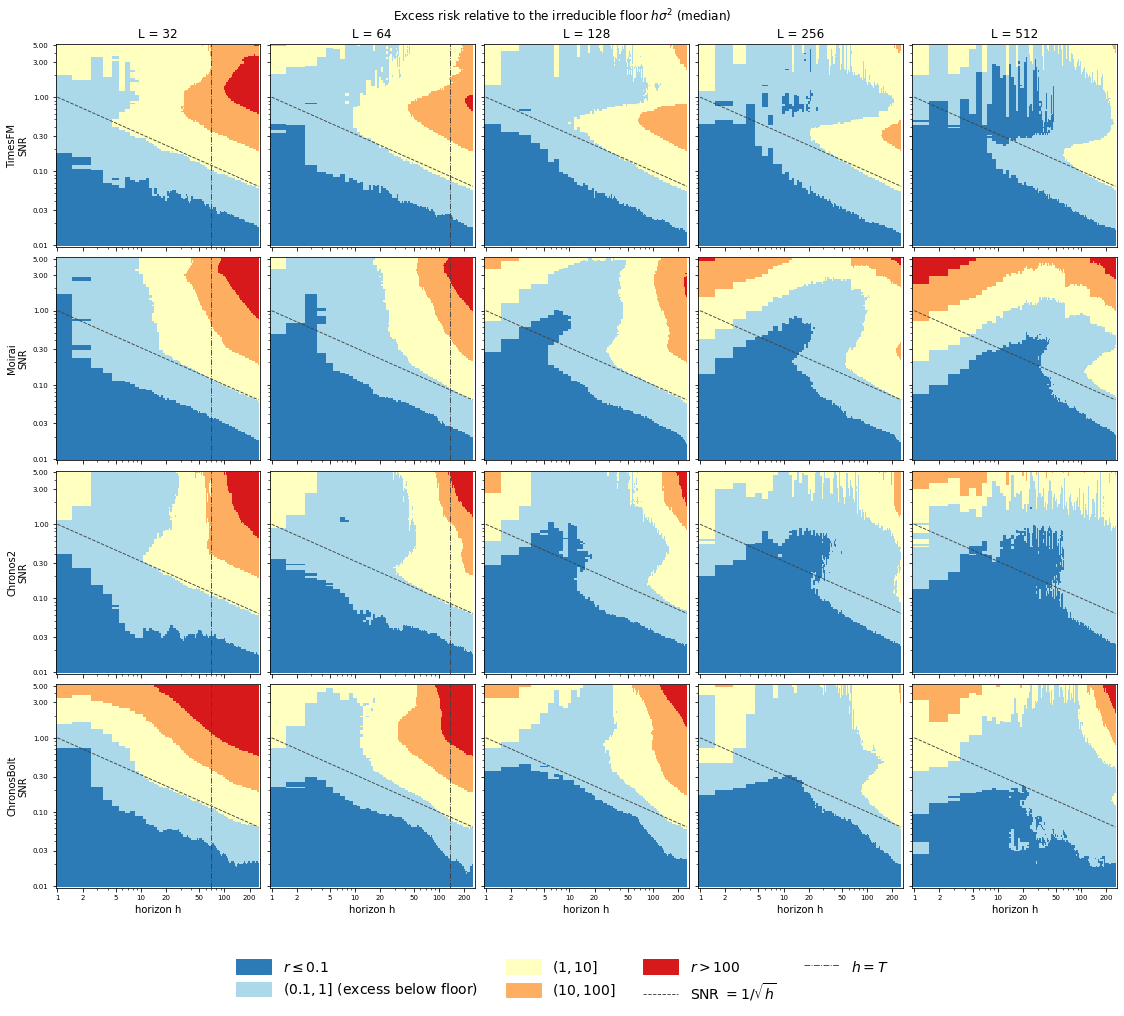

In [6]:
fig, axes = plt.subplots(len(model_order), len(context_lengths),
                         figsize=(3.1 * len(context_lengths), 3.1 * len(model_order)),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)

for row, model_name in enumerate(model_order):
    for col, L in enumerate(context_lengths):
        part = r_table[(r_table["model"] == model_name) & (r_table["L"] == L)]
        r_grid = part.pivot(index="snr", columns="horizon", values="r_model_median")
        r_grid = r_grid.reindex(index=snr_values, columns=horizon_values).to_numpy().astype(float)

        # put every cell in one of the five bands, missing cells stay blank
        band_grid = np.digitize(r_grid, band_edges, right=True).astype(float)
        band_grid[~np.isfinite(r_grid)] = np.nan

        ax = axes[row, col]
        ax.pcolormesh(horizon_values, snr_values, np.ma.masked_invalid(band_grid),
                      cmap=colormap, norm=color_steps, shading="nearest")

        # reference lines: naive error = noise at SNR = 1/sqrt(h), plug-in error = noise at h = T
        ax.plot(horizon_values, 1 / np.sqrt(horizon_values), color=".25", linestyle="--", linewidth=0.9)
        ax.axvline((L - 1) / 0.455, color=".25", linestyle="-.", linewidth=0.9) 

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.set_xticks([1, 2, 5, 10, 20, 50, 100, 200])
        ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1, 3, 5])
        ax.set_xlim(horizon_values.min() * 0.95, horizon_values.max() * 1.05)
        ax.set_ylim(snr_values.min() * 0.95, snr_values.max() * 1.05)
        ax.tick_params(labelsize=7)
        if row == 0:
            ax.set_title(f"L = {L}")
        if col == 0:
            ax.set_ylabel(f"{model_labels[model_name]}\nSNR")
        if row == len(model_order) - 1:
            ax.set_xlabel("horizon h")

fig.suptitle("Excess risk relative to the irreducible floor $h\\sigma^2$ (median)", y=1.02)
fig.legend(handles=legend_items, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.11),
           fontsize=legend_fontsize, handlelength=2.5, handleheight=1.2, columnspacing=2.0)

fig.savefig(f"{results_folder}/fig2_excess_risk_median.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
# Table 4, median over the walks in a cell: median over all cells per L
print("=== Table 4, median over the walks in a cell ===")

print("excess risk of the model")
model_table = r_table.pivot_table(index="model", columns="L", values="r_model_median", aggfunc="median")
print(model_table.reindex(model_order).round(2).to_string())

# plug-in and naive are the same for every model, so take them from one model
reference = r_table[r_table["model"] == model_order[0]]
reference_table = pd.DataFrame({
    "plug-in": reference.groupby("L")["r_plugin_median"].median(),
    "naive":   reference.groupby("L")["r_naive_median"].median()}).T
print("\nexcess risk of the reference forecasters")
print(reference_table.round(2).to_string())

print("\nratio model / plug-in  (median of the per-cell ratios, not the quotient of the rows above)")
ratio_table = r_table.pivot_table(index="model", columns="L", values="r_ratio_median", aggfunc="median")
print(ratio_table.reindex(model_order).round(2).to_string())

=== Table 4, median over the walks in a cell ===
excess risk of the model
L             32    64    128   256   512
model                                    
TimesFM      3.50  2.50  1.33  0.91  0.48
Moirai       3.01  1.95  1.62  0.98  0.57
Chronos2     2.84  1.38  0.63  0.39  0.21
ChronosBOLT  4.93  3.01  1.83  0.70  0.43

excess risk of the reference forecasters
L         32    64    128   256   512
plug-in  1.68  1.07  0.39  0.20  0.12
naive    4.78  4.78  4.78  4.78  4.78

ratio model / plug-in  (median of the per-cell ratios, not the quotient of the rows above)
L             32    64    128   256   512
model                                    
TimesFM      4.66  4.33  5.14  5.88  4.89
Moirai       3.58  3.48  7.87  7.18  5.26
Chronos2     3.40  2.59  2.63  2.29  1.94
ChronosBOLT  4.43  5.46  9.04  5.64  4.87
